# HW8 Graph Explorer: matrices, walkers, PageRank and flow

**Algorithmics, 2026.** Run all cells in order in Colab. No data download,
Drive mount, API key or separate Python module is required. All input graphs
are original synthetic course examples; no real student data are used.

This notebook supplies data, drawing and checks, not your closure, walk,
PageRank or Edmonds-Karp implementations. Complete those in new cells.
The optional library flow check is for T4, **after** the hand trace.
Use a concise report with selected figures, not the entire notebook output.

Locally, install `numpy matplotlib networkx scipy ipython` in a virtual
environment. These libraries are normally available in Colab.


In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
%matplotlib inline
print("NumPy", np.__version__, "NetworkX", nx.__version__)


NumPy 2.1.3 NetworkX 3.7


## Data, plotting and reference checks

The following definition cell is self-contained. Input node IDs are stable;
matrix rows follow the `nodes` list returned by `graph_arrays`.
Drawing functions return a Matplotlib axis, so save a report figure with
`ax.figure.savefig("my_figure.png", dpi=160, bbox_inches="tight")`.


In [2]:
#@title Graph inputs, drawing and checkers (run once)
"""HW8 inputs, drawing and reference checks; no student algorithm solutions.

All data are original synthetic course examples. Node order is insertion order.
Dependencies: numpy, matplotlib, networkx; scipy for the PageRank reference.
"""
import json
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.colors import Normalize, to_rgb
import networkx as nx
import numpy as np


def mini_web(variant="base"):
    """A fixed weighted directed web. 'escape' adds only Partner B -> Home."""
    if variant not in ("base", "escape"):
        raise ValueError("variant must be 'base' or 'escape'")
    names = ["Home", "Courses", "Algorithms", "Trees", "Graphs", "Research",
             "Projects", "People", "Updates", "Partner A", "Partner B", "Exit"]
    positions = [(0, 2), (-2, 1), (-3, 0), (-2, -1), (-1, 0),
                 (1, 1), (2, 0), (3, 1), (1, -1), (3, -1), (4, -2), (0, -2)]
    groups = [0, 1, 1, 1, 1, 2, 2, 2, 2, 3, 3, 4]
    graph = nx.DiGraph(name=f"mini-web-{variant}")
    for node, (label, pos, group) in enumerate(zip(names, positions, groups)):
        graph.add_node(node, label=label, pos=pos, group=group)
    edges = [(0, 1, 3), (0, 5, 1), (1, 2, 3), (1, 3, 1), (1, 4, 1),
             (2, 3, 2), (2, 4, 1), (3, 2, 1), (3, 4, 2), (4, 1, 1),
             (4, 5, 1), (5, 6, 4), (5, 7, 1), (6, 5, 1), (6, 7, 1),
             (6, 8, 1), (7, 5, 1), (7, 9, 1), (8, 5, 1), (8, 11, 1),
             (8, 9, 1), (9, 10, 1), (10, 9, 1)]
    graph.add_weighted_edges_from(edges)
    if variant == "escape":
        graph.add_edge(10, 0, weight=1)
    return graph


def cluster_graph(n=128, seed=8):
    """Four internally connected blocks, with inter-block links only forward."""
    if n < 16 or n % 4:
        raise ValueError("n must be a multiple of four, at least 16")
    rng = np.random.default_rng(seed)
    graph = nx.DiGraph(name=f"clusters-{n}-seed-{seed}")
    size = n // 4
    centres = [(-2, 1.5), (2, 1.5), (-2, -1.5), (2, -1.5)]
    for node in range(n):
        group, local = divmod(node, size)
        angle = 2 * np.pi * local / size
        cx, cy = centres[group]
        graph.add_node(node, label=str(node), group=group,
                       pos=(cx + np.cos(angle), cy + np.sin(angle)))
    for group in range(4):
        members = np.arange(group * size, (group + 1) * size)
        for local, u in enumerate(members):
            targets = {int(members[(local + 1) % size])}
            candidates = members[members != u]
            targets.update(map(int, rng.choice(candidates, min(3, size - 1), replace=False)))
            for v in sorted(targets):
                graph.add_edge(int(u), v, weight=int(rng.choice([1, 2, 5, 10])))
    for a, b in [(0, 1), (0, 2), (1, 2), (2, 3)]:
        for _ in range(2):
            u = int(rng.integers(a * size, (a + 1) * size))
            v = int(rng.integers(b * size, (b + 1) * size))
            graph.add_edge(u, v, weight=1)
    return graph


def small_allocation():
    """Two students, two one-seat sessions, source and sink. All capacities 1."""
    graph = nx.DiGraph(name="allocation-small", source="s", sink="t")
    nodes = [("s", (0, 0), "source"), ("A", (1, 1), "student"),
             ("B", (1, -1), "student"), ("X", (2, 1), "session"),
             ("Y", (2, -1), "session"), ("t", (3, 0), "sink")]
    for node, pos, kind in nodes:
        graph.add_node(node, pos=pos, label=node, kind=kind)
    for u, v in [("s", "A"), ("s", "B"), ("A", "X"), ("A", "Y"),
                 ("B", "X"), ("X", "t"), ("Y", "t")]:
        graph.add_edge(u, v, capacity=1)
    return graph


def allocation_network(seed=8):
    """200 fictional students and 12 sessions. Edges mean availability, not rank."""
    rng = np.random.default_rng(seed)
    graph = nx.DiGraph(name=f"allocation-200-seed-{seed}", source="s", sink="t")
    graph.add_node("s", kind="source", label="source", pos=(0, 0))
    for i in range(200):
        student = f"u{i:03d}"
        graph.add_node(student, kind="student", label=student, pos=(1, 1 - 2 * i / 199))
    for j in range(12):
        session = f"g{j:02d}"
        graph.add_node(session, kind="session", label=session, pos=(2, 1 - 2 * j / 11))
    graph.add_node("t", kind="sink", label="sink", pos=(3, 0))
    for j in range(12):
        graph.add_edge(f"g{j:02d}", "t", capacity=20 if j < 2 else 16)
    for i in range(200):
        student = f"u{i:03d}"
        graph.add_edge("s", student, capacity=1)
        if i < 60:
            choices = [0, 1]
        else:
            guaranteed = 2 + (i - 60) % 10
            others = [j for j in range(2, 12) if j != guaranteed]
            choices = sorted([guaranteed, *map(int, rng.choice(others, 2, replace=False))])
        for j in choices:
            graph.add_edge(student, f"g{j:02d}", capacity=1)
    return graph


def graph_arrays(graph):
    """Return (node_order, Boolean adjacency, weights/capacities); no normalisation."""
    nodes = list(graph)
    attribute = "capacity" if "source" in graph.graph else "weight"
    weights = nx.to_numpy_array(graph, nodelist=nodes, weight=attribute, dtype=float)
    return nodes, weights > 0, weights


def draw_graph(graph, values=None, ax=None, title=None, edge_labels=False,
               labels=None, cut=None, value_max=None):
    """Fixed positions. Probability values are keyed by node ID, not row number."""
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 7), constrained_layout=True)
    if labels is None:
        labels = len(graph) <= 24
    nodes = list(graph)
    pos = nx.get_node_attributes(graph, "pos")
    if len(pos) != len(nodes):
        pos = nx.spring_layout(graph, seed=8)
    colours = ["#d6e8f5"] * len(nodes)
    sizes = [1250 if labels else 35] * len(nodes)
    if values is not None:
        data = np.array([values[u] for u in nodes], dtype=float)
        if np.any(~np.isfinite(data)) or np.any(data < 0):
            raise ValueError("drawing values must be finite and nonnegative")
        upper = max(float(data.max()), 1e-15) if value_max is None else float(value_max)
        if not np.isfinite(upper) or upper <= 0 or data.max() > upper:
            raise ValueError("value_max must be positive and include all drawing values")
        norm = Normalize(vmin=0, vmax=upper)
        colours = plt.get_cmap("viridis")(norm(data))
        sizes = (1250 if labels else 35) + 1000 * data / upper
        ax.figure.colorbar(plt.cm.ScalarMappable(norm=norm, cmap="viridis"), ax=ax,
                          label="probability", shrink=0.7)
    if cut is not None:
        colours = ["#b2d8ef" if u in cut else "#f4c5a9" for u in nodes]
    nx.draw_networkx_nodes(graph, pos, nodelist=nodes, node_color=colours,
                           node_size=sizes, edgecolors="#333333", linewidths=0.6, ax=ax)
    nx.draw_networkx_edges(graph, pos, ax=ax, node_size=sizes, nodelist=nodes,
                           arrows=True, arrowsize=14 if labels else 7,
                           alpha=0.7 if labels else 0.15, connectionstyle="arc3,rad=0.10")
    if labels:
        text = {u: f"{u}\n{graph.nodes[u]['label']}" if str(u) != graph.nodes[u].get("label", str(u))
                else str(u) for u in nodes}
        for u, colour in zip(nodes, colours):
            luminance = np.dot(to_rgb(colour), [0.2126, 0.7152, 0.0722])
            font_size = 7 if max(map(len, text[u].splitlines())) > 8 else 8
            nx.draw_networkx_labels(graph, pos, labels={u: text[u]}, font_size=font_size,
                                   font_color="white" if luminance < 0.5 else "black", ax=ax)
    if edge_labels:
        attribute = "capacity" if "source" in graph.graph else "weight"
        text = {(u, v): data.get("display", data.get(attribute, 1))
                for u, v, data in graph.edges(data=True)}
        nx.draw_networkx_edge_labels(graph, pos, edge_labels=text, font_size=8,
                                      connectionstyle="arc3,rad=0.10", ax=ax)
    ax.set_title(title or graph.name)
    ax.margins(0.16)
    ax.set_axis_off()
    return ax


def draw_matrix(matrix, nodes=None, title="Matrix", ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(6, 5), constrained_layout=True)
    matrix = np.asarray(matrix)
    image = ax.imshow(matrix, interpolation="nearest", cmap="viridis", origin="upper")
    ax.figure.colorbar(image, ax=ax, shrink=0.8)
    ax.set(title=title, xlabel="destination column j", ylabel="source row i")
    if nodes is not None and len(nodes) <= 16:
        ax.set_xticks(range(len(nodes)), nodes)
        ax.set_yticks(range(len(nodes)), nodes)
    return ax


def draw_flow(graph, flow, cut=None, ax=None, title="Flow / capacity"):
    shown = graph.copy()
    for u, v, data in shown.edges(data=True):
        data["display"] = f"{flow.get(u, {}).get(v, 0):g}/{data['capacity']:g}"
    return draw_graph(shown, cut=cut, ax=ax, title=title, edge_labels=True)


def draw_residual(graph, flow, ax=None, title="Residual capacities"):
    """Draw a supplied flow's residual network; does not find augmenting paths."""
    residual = nx.DiGraph(name=title, source=graph.graph["source"], sink=graph.graph["sink"])
    residual.add_nodes_from(graph.nodes(data=True))
    for u, v, data in graph.edges(data=True):
        value = flow.get(u, {}).get(v, 0)
        if not 0 <= value <= data["capacity"]:
            raise ValueError("flow violates a capacity")
        for a, b, amount in [(u, v, data["capacity"] - value), (v, u, value)]:
            if amount > 0:
                previous = residual.get_edge_data(a, b, {}).get("capacity", 0)
                residual.add_edge(a, b, capacity=previous + amount)
    return draw_graph(residual, ax=ax, title=title, edge_labels=True)


def draw_allocation(graph, flow, ax=None, title="Assigned students and session capacities"):
    """Readable summary of the full allocation; not a 214-node edge-label plot."""
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4), constrained_layout=True)
    sessions = [u for u, data in graph.nodes(data=True) if data.get("kind") == "session"]
    sink = graph.graph["sink"]
    capacity = [graph[u][sink]["capacity"] for u in sessions]
    assigned = [sum(flow.get(v, {}).get(u, 0) for v in graph.predecessors(u)) for u in sessions]
    x = np.arange(len(sessions))
    ax.bar(x, capacity, color="#dddddd", edgecolor="#777777", label="capacity")
    ax.bar(x, assigned, width=0.6, color="#247d83", label="assigned")
    ax.set_xticks(x, sessions)
    ax.set(title=title, ylabel="students")
    ax.legend()
    return ax


def check_distribution(vector, n):
    vector = np.asarray(vector, dtype=float)
    if vector.shape != (n,) or not np.isfinite(vector).all() or (vector < -1e-12).any():
        raise AssertionError("distribution must be a finite nonnegative vector of length n")
    np.testing.assert_allclose(vector.sum(), 1, atol=1e-10, rtol=0)


def check_closure(graph, closure, nodes):
    """Validate reflexive reachability against library traversals."""
    if len(nodes) != len(graph) or set(nodes) != set(graph):
        raise AssertionError("node order must contain every vertex exactly once")
    closure = np.asarray(closure)
    if closure.shape != (len(nodes), len(nodes)) or not np.isin(closure, [0, 1]).all():
        raise AssertionError("closure must be an n-by-n Boolean/0-1 matrix")
    for i, u in enumerate(nodes):
        reachable = nx.descendants(graph, u) | {u}
        np.testing.assert_array_equal(closure[i], [v in reachable for v in nodes])


def check_pagerank(graph, ranks, rho=0.15, tolerance=1e-8):
    """Library reference only: rho is teleport probability, not NetworkX alpha."""
    if not 0 < rho < 1:
        raise ValueError("this reference check requires 0 < rho < 1")
    if set(ranks) != set(graph):
        raise AssertionError("one rank per vertex is required")
    check_distribution([ranks[u] for u in graph], len(graph))
    expected = nx.pagerank(graph, alpha=1 - rho, weight="weight",
                           tol=1e-13 / len(graph), max_iter=10000)
    np.testing.assert_allclose([ranks[u] for u in graph], [expected[u] for u in graph],
                               rtol=0, atol=tolerance)


def check_flow(graph, flow, source_side, tolerance=1e-9):
    """Check feasible nonnegative original-edge flows and an equal-capacity cut.

    A certificate checker, not a solver. Missing edge entries mean zero.
    Do not pass a signed residual-flow dictionary without converting it first.
    """
    s, t = graph.graph["source"], graph.graph["sink"]
    side = set(source_side)
    if not side <= set(graph) or s not in side or t in side:
        raise AssertionError("cut must contain source, exclude sink, and use valid nodes")
    for u, targets in flow.items():
        for v, value in targets.items():
            if not np.isfinite(value) or (not graph.has_edge(u, v) and value != 0):
                raise AssertionError("nonzero flows must be finite and on original edges")
    balance = dict.fromkeys(graph, 0.0)
    for u, v, data in graph.edges(data=True):
        value = flow.get(u, {}).get(v, 0)
        if not -tolerance <= value <= data["capacity"] + tolerance:
            raise AssertionError("capacity constraint violated")
        balance[u] -= value
        balance[v] += value
    for u in graph:
        if u not in (s, t) and abs(balance[u]) > tolerance:
            raise AssertionError(f"flow conservation violated at {u}")
    value = -balance[s]
    cut_capacity = sum(data["capacity"] for u, v, data in graph.edges(data=True)
                       if u in side and v not in side)
    np.testing.assert_allclose([value, balance[t]], cut_capacity, rtol=0, atol=tolerance)
    return {"flow_value": value, "cut_capacity": cut_capacity}


def export_graphs(graphs, path="HW8_graph_data.json"):
    """Portable node/edge records; no solutions. Preserve node IDs and order."""
    data = {"format": "HW8-graphs-v1", "graphs": {}}
    for name, graph in graphs.items():
        data["graphs"][name] = {
            "directed": True, "metadata": dict(graph.graph),
            "nodes": [{"id": u, **attrs} for u, attrs in graph.nodes(data=True)],
            "edges": [{"source": u, "target": v, **attrs}
                      for u, v, attrs in graph.edges(data=True)],
        }
    Path(path).write_text(json.dumps(data, indent=2) + "\n", encoding="utf-8")
    return Path(path)


def homework_graphs():
    """The exact common inputs exported for other languages too."""
    graphs = {"web_base": mini_web(), "web_escape": mini_web("escape")}
    graphs.update({f"clusters_{n}": cluster_graph(n, seed=8) for n in (64, 128, 256, 512)})
    graphs.update(allocation_small=small_allocation(), allocation_large=allocation_network(seed=8))
    return graphs


In [3]:
graphs = homework_graphs()
for name, graph in graphs.items():
    print(f"{name:20s} {len(graph):4d} vertices, {graph.number_of_edges():4d} edges")
web = graphs["web_base"]
nodes, A, W = graph_arrays(web)
print("Row/column order:", nodes)
print("Labels:", {u: web.nodes[u]["label"] for u in nodes})


web_base               12 vertices,   23 edges
web_escape             12 vertices,   24 edges
clusters_64            64 vertices,  255 edges
clusters_128          128 vertices,  503 edges
clusters_256          256 vertices, 1023 edges
clusters_512          512 vertices, 2046 edges
allocation_small        6 vertices,    7 edges
allocation_large      214 vertices,  752 edges
Row/column order: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11]
Labels: {0: 'Home', 1: 'Courses', 2: 'Algorithms', 3: 'Trees', 4: 'Graphs', 5: 'Research', 6: 'Projects', 7: 'People', 8: 'Updates', 9: 'Partner A', 10: 'Partner B', 11: 'Exit'}


## A small weighted web, with fixed drawing positions

Numbers on edges are **weights**, not probabilities or capacities. For a
weighted walk, normalise the outgoing weights at each source. For an
unweighted walk, choose uniformly among its outgoing neighbours. You must
handle a vertex with no outgoing edges explicitly.

`mini_web("escape")` differs by exactly one extra edge, Partner B -> Home.
The layout is identical, so changing the graph does not move its vertices.


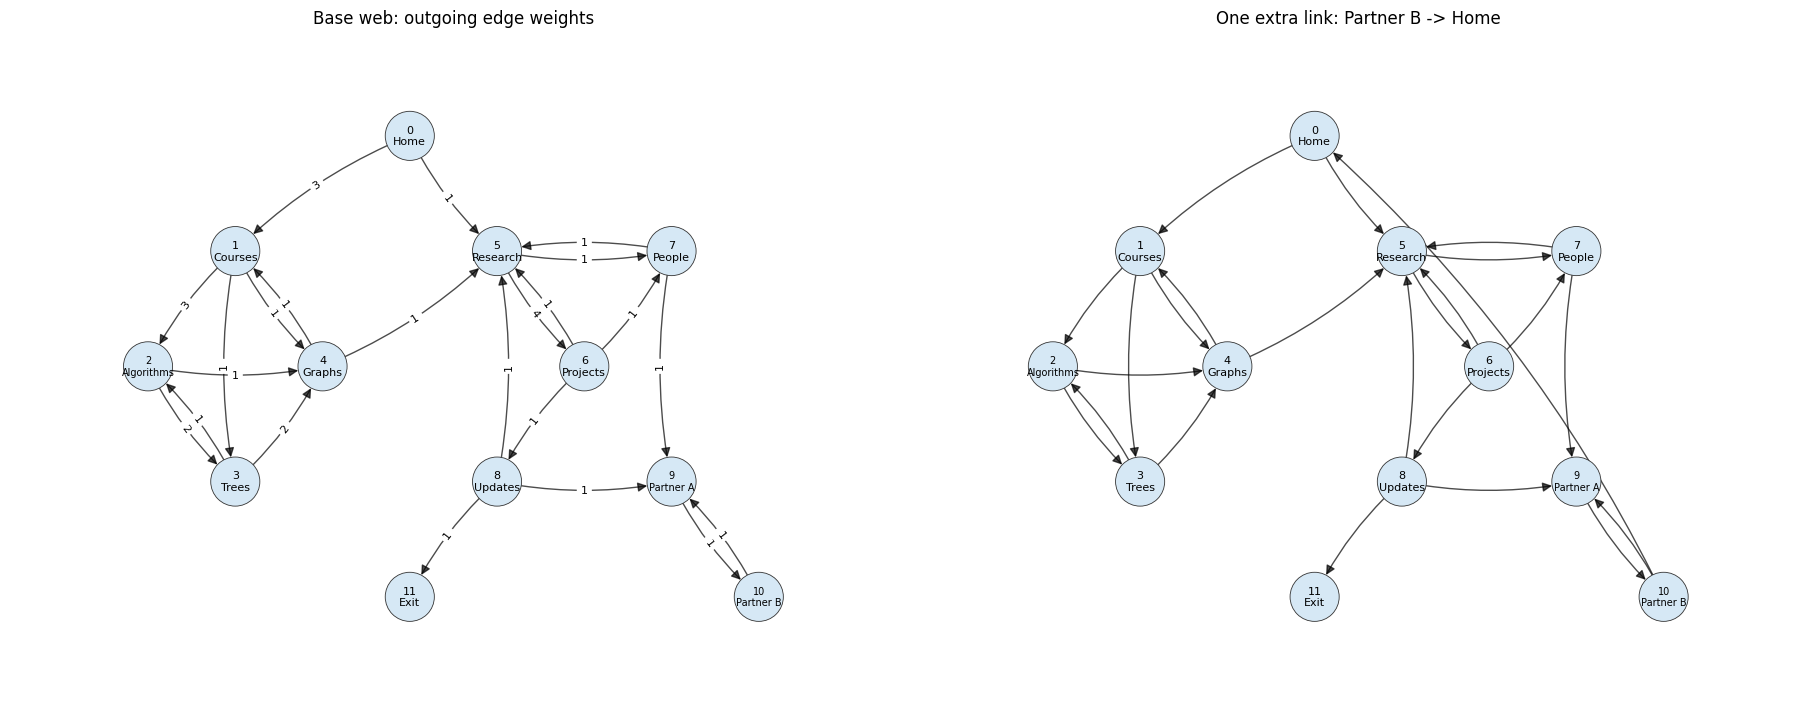

Home's outgoing weights: {1: 3, 5: 1}


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7), constrained_layout=True)
draw_graph(web, ax=axes[0], edge_labels=True, title="Base web: outgoing edge weights")
draw_graph(graphs["web_escape"], ax=axes[1], title="One extra link: Partner B -> Home")
plt.show()
print("Home's outgoing weights:", {v: web[0][v]["weight"] for v in web.successors(0)})


## Adjacency and weights: the same row/column convention

Row = source; column = destination. `A` is Boolean, `W` is floating point.
Use an integer copy such as `A.astype(np.int64)` when counting walks by
ordinary multiplication. Boolean reachability and walk counts are different.
For closure, threshold after every ordinary product to avoid accumulating
huge counts, and do not use an 8-bit integer accumulator.

Your T1 functions can return arrays for `draw_matrix` and `check_closure`.
This notebook does not calculate the assignment's powers or closure for you.


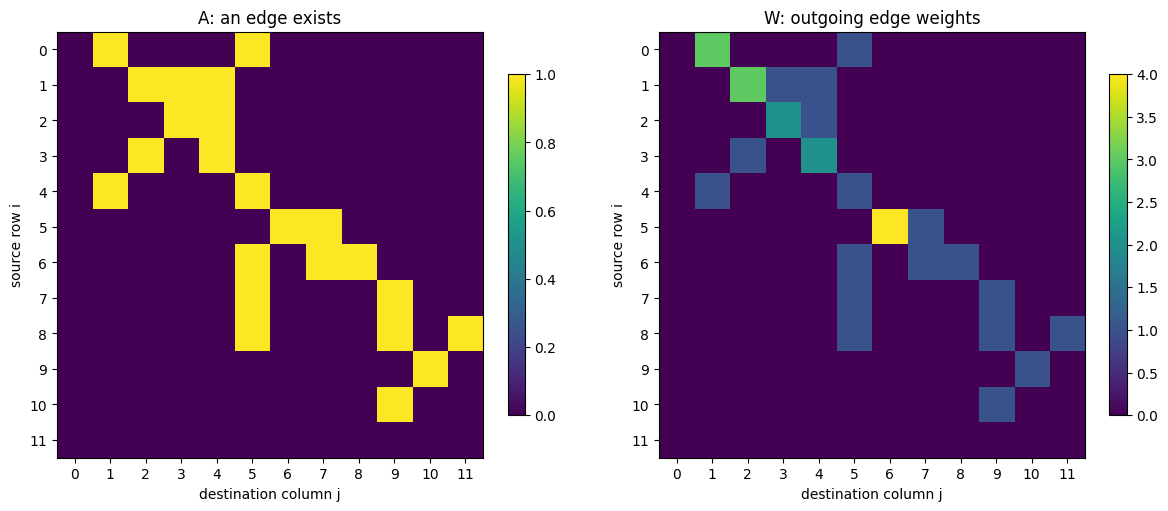

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
draw_matrix(A, nodes, title="A: an edge exists", ax=axes[0])
draw_matrix(W, nodes, title="W: outgoing edge weights", ax=axes[1])
plt.show()


## Matrix syntax on a separate two-state example

This is a syntax demonstration, not the course graph's transition matrix.
A row distribution `p` advances by `p @ P`, not `P @ p`.
Build the actual web's P yourself, including its dangling row.


One step in the separate two-state example: [0.8 0.2]


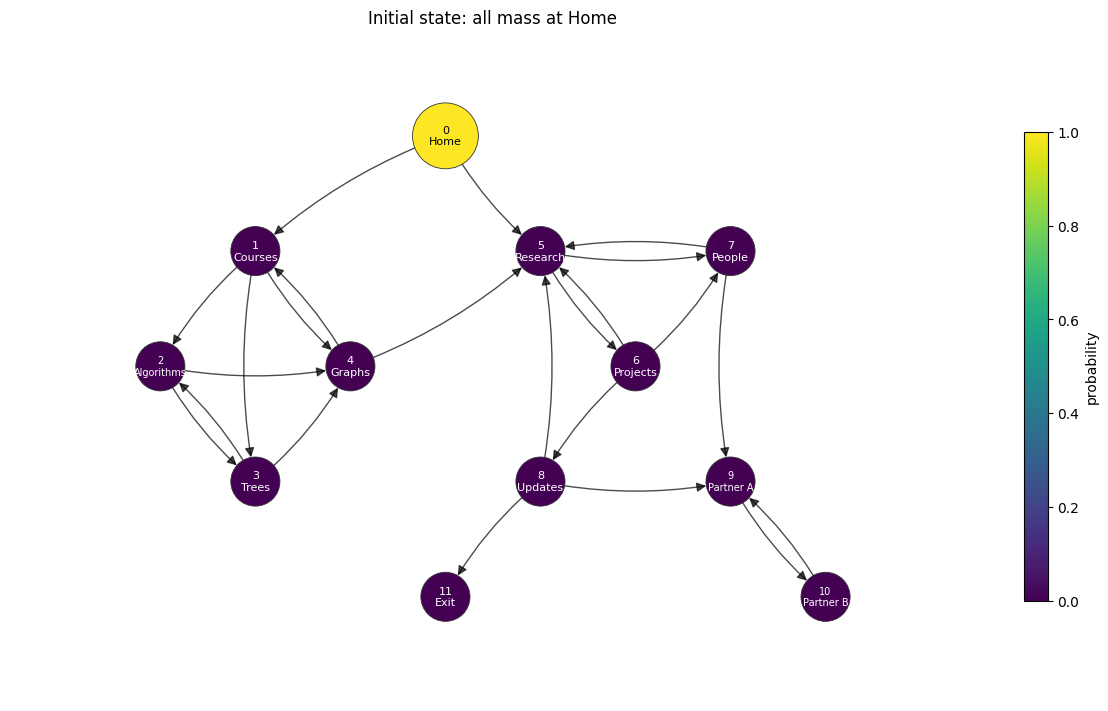

In [6]:
demo_P = np.array([[0.8, 0.2], [0.3, 0.7]])
demo_p = np.array([1.0, 0.0])
demo_next = demo_p @ demo_P
check_distribution(demo_next, 2)
print("One step in the separate two-state example:", demo_next)

# Example of displaying a supplied distribution: the initial state only.
initial = np.zeros(len(nodes))
initial[nodes.index(0)] = 1
check_distribution(initial, len(nodes))
draw_graph(web, values=dict(zip(nodes, initial)), title="Initial state: all mass at Home")
plt.show()


## Larger examples: diagrams for structure, matrices for scale

`cluster_graph(n, seed=8)` has four groups with internal cycles and some
one-way inter-group links. Sizes 64, 128, 256, 512 are T1 inputs. The
256-vertex input is also used in T3. These are reproducible independent
instances, not necessarily nested induced subgraphs.

At larger sizes, a matrix heatmap or group totals are more readable than
labelling every vertex and edge. Group attributes describe the generator;
your reachability/SCC result should be checked, not assumed from colours.


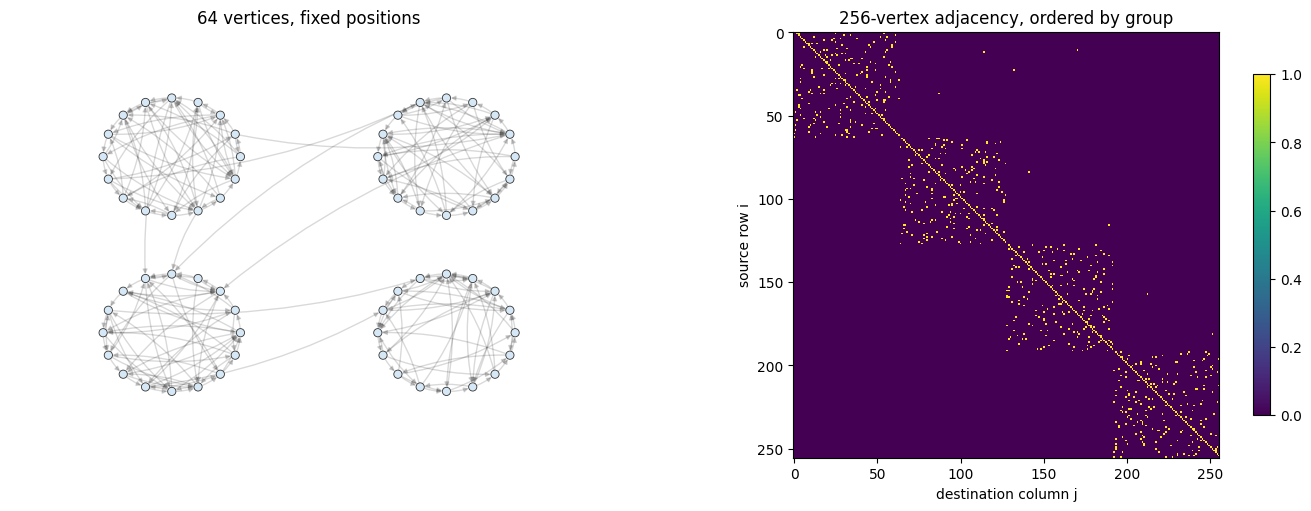

Extra closure checks: 17 chain vertices; 3 cycle/isolate vertices


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
draw_graph(graphs["clusters_64"], ax=axes[0], labels=False, title="64 vertices, fixed positions")
large_nodes, large_A, large_W = graph_arrays(graphs["clusters_256"])
draw_matrix(large_A, title="256-vertex adjacency, ordered by group", ax=axes[1])
plt.show()

# T1 edge-case inputs. The isolated vertex must be present explicitly.
chain = nx.path_graph(17, create_using=nx.DiGraph)
cycle_and_isolate = nx.DiGraph([(0, 1), (1, 0)])
cycle_and_isolate.add_node(2)
print("Extra closure checks:", len(chain), "chain vertices;", len(cycle_and_isolate), "cycle/isolate vertices")


## Calls to use after writing your algorithms

Keep these examples in your own solution cells, replacing variable names:

```python
check_closure(web, my_closure, nodes)
check_distribution(my_probability_vector, len(nodes))
check_pagerank(web, dict(zip(nodes, my_rank_vector)), rho=0.10)
ax = draw_graph(web, values=dict(zip(nodes, my_rank_vector)))
ax.figure.savefig("pagerank.png", dpi=160, bbox_inches="tight")
```

For comparable probability colours and node sizes across several plots,
pass the same `value_max` to `draw_graph`, at least as large as every
displayed probability in the comparison.

The PageRank checker uses **uniform** teleportation/dangling repair and
positive `rho`; it is not a convergence test for the rho=0 experiment.
For B1, call NetworkX with the same `personalization` and `dangling` mapping.
NetworkX's `alpha` is the link-following probability: `alpha = 1 - rho`.

T2 compares **endpoints after t transitions** to the t-step distribution.
T3 compares **long-run visit counts** to a stationary distribution. Do not
accidentally count visits in T2 or restart the walker at every step in T3.


## Small maximum flow: solve the hand trace first

A and B are students; X and Y are one-seat sessions. Edge labels are now
**capacities**, not stochastic weights. The task fixes the first augmenting
path as s -> A -> X -> t. Find the next path in the residual network yourself.

Store flow on original edges as a dictionary of dictionaries, for example
`flow[u][v]`. Missing edges mean zero. A reverse residual edge does not mean
a negative flow on an original edge in this representation.


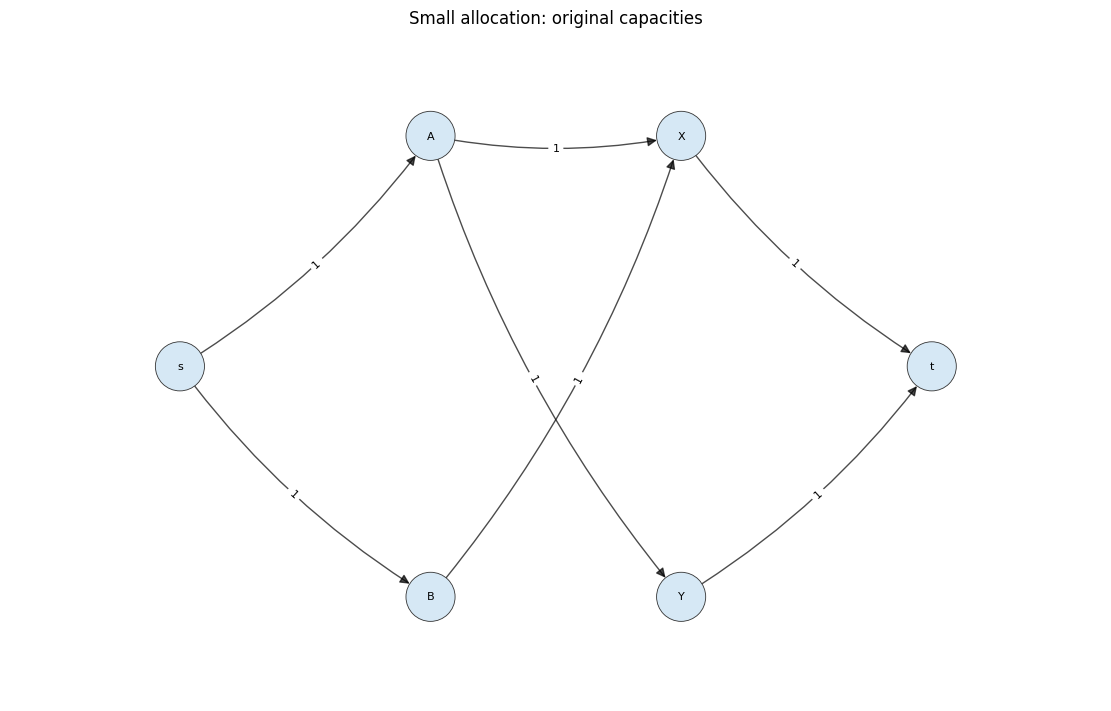

In [8]:
small = graphs["allocation_small"]
draw_graph(small, edge_labels=True, title="Small allocation: original capacities")
plt.show()


Enter your hand-computed flow and source-side cut into your own cell:

```python
check_flow(small, my_flow, my_source_side)
draw_flow(small, my_flow, cut=my_source_side)
draw_residual(small, my_flow)
plt.show()
```

The checker tests capacity constraints, conservation and equality of flow
value with your cut capacity. It does not find the flow or cut for you.
The following **optional** library check is permitted in T4, after your
hand solution. The default is off, so running all starter cells reveals
inputs and plotting examples, not the small flow's answer.


In [9]:
RUN_SMALL_FLOW_REFERENCE = False
if RUN_SMALL_FLOW_REFERENCE:
    value, reference_flow = nx.maximum_flow(small, "s", "t", capacity="capacity")
    cut_value, (source_side, _) = nx.minimum_cut(small, "s", "t", capacity="capacity")
    print(check_flow(small, reference_flow, source_side))
    fig, axes = plt.subplots(1, 2, figsize=(14, 5), constrained_layout=True)
    draw_flow(small, reference_flow, cut=source_side, ax=axes[0])
    draw_residual(small, reference_flow, ax=axes[1])
    plt.show()


## Larger allocation: keep the original data unchanged

In T5, implement Edmonds-Karp yourself, then validate it with `check_flow`
and (optionally) NetworkX. Use the original network for the baseline and
a fresh `large.copy()` for each separate capacity experiment. Do not carry
a previous residual graph or flow into the next run.

There are 200 synthetic students, 12 sessions, plus source and sink. A
compatibility edge means a session is possible, not preferred. Do not use
real student availability. Count BFS residual-edge examinations consistently,
including unsuccessful tests, and state your convention.


Students: 200 Sessions: 12
Total seats: 200
u000 can attend ['g00', 'g01']
u001 can attend ['g00', 'g01']
u002 can attend ['g00', 'g01']
u003 can attend ['g00', 'g01']
u004 can attend ['g00', 'g01']


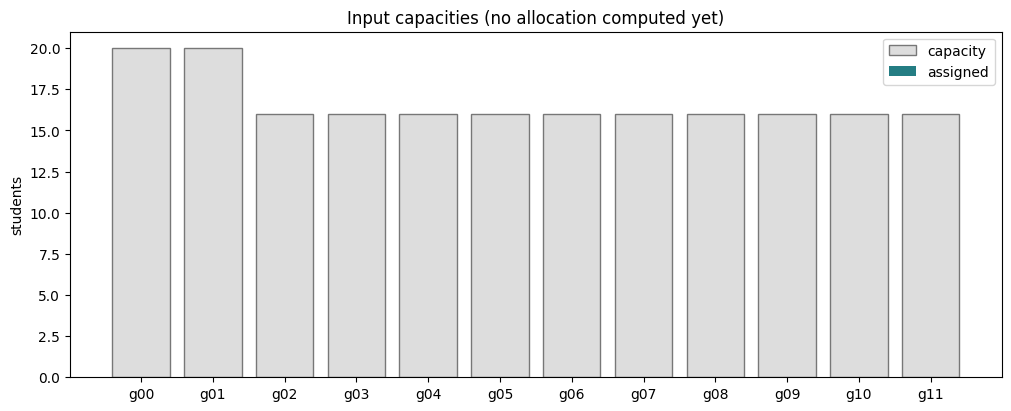

In [10]:
large = graphs["allocation_large"]
students = [u for u, data in large.nodes(data=True) if data.get("kind") == "student"]
sessions = [u for u, data in large.nodes(data=True) if data.get("kind") == "session"]
print("Students:", len(students), "Sessions:", len(sessions))
print("Total seats:", sum(large[u]["t"]["capacity"] for u in sessions))
for u in students[:5]:
    print(u, "can attend", list(large.successors(u)))
draw_allocation(large, {}, title="Input capacities (no allocation computed yet)")
plt.show()


Display your results with `draw_allocation(large, my_flow)`. For a modified
capacity scenario pass that **modified graph**, not the original one.
The grey bars are capacities; the narrower coloured bars show assignments.
For a small subgraph use `draw_graph` with preserved node positions. Label
any subset as a subset, not the whole allocation.

## Export for another language

The JSON below contains all eight fixed inputs: ordered node records,
directed edge records, weights/capacities, drawing positions and metadata.
IDs are integers for the web/cluster graphs and strings for allocation.
Rows without outgoing edges are retained in the node list. Files contain
inputs only, no rankings, closures, flows or solutions.


In [11]:
exported = export_graphs(graphs)
print("Exported", exported.name, "with", len(graphs), "input graphs.")
# To download in Colab, uncomment:
# from google.colab import files
# files.download(str(exported))


Exported HW8_graph_data.json with 8 input graphs.


## Reporting and references

Save a few legible figures and short result tables. Keep node positions,
node order, seed and conventions fixed for comparisons. Report checking and
drawing separately from algorithm timing. No live external dataset is
needed to complete the five tasks.

- [NetworkX PageRank reference](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.link_analysis.pagerank_alg.pagerank.html)
- [NetworkX Edmonds-Karp reference](https://networkx.org/documentation/stable/reference/algorithms/generated/networkx.algorithms.flow.edmonds_karp.html)

Data and illustrations here are original synthetic course material.
